# Stage 3 — The forecast target and the features

This notebook turns the weekly panel from stage 2 into the table the models are fitted on:
one row per week ending Friday, holding **next week's volatility** as the target and, as
features, only things known at the close of that Friday.

| Step | What it does |
|---|---|
| 1 | the modelling sample and the chronological splits |
| 2 | the target: `log_rv` of week t+1 |
| 3 | HAR inputs: past volatility over 1, 4 and 12 weeks |
| 4 | 12 oil-market features from the EIA weekly series |
| 5 | the WTI futures expiry flag |
| 6 | standardising, the drift check and clipping |
| 7 | PCA on the oil features |
| 8 | regimes from a Gaussian mixture |
| 9 | checks, the hand-check, and saving |

**Output:** `data/processed/features.csv` (git-ignored: it contains price-derived data),
plus `scaler_params.csv`, `feature_drift.csv`, `clip_limits.csv` and `pca_loadings.csv` in
`results/tables/`.

Three rules hold throughout, and the checks at the end verify them:

1. **No look-ahead.** Every feature for week t uses only information available at the close
   of Friday t. The EIA alignment is the one built in stage 2, so week t sees the EIA week
   ending t-7 at the latest; the seasonal averages use earlier years only; the futures
   expiry calendar is published years in advance.
2. **Training only.** The scaler, the clipping limits, the PCA and the mixture are all
   fitted on training rows and then applied everywhere.
3. **Nothing is explored outside the training rows.** Correlations with the target are
   shown for training weeks only; 2015-2026 is not looked at in this stage.

The feature list is **frozen** after this notebook: it lives in `src/config.py`.

*Written with the help of Claude (Anthropic); declared in the paper appendix.*

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder containing src/) so `src` can be imported
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import (CLIP_LIMITS_PATH, CLIP_PERCENTILES, DRIFT_FLAG_PCT,
                        EXPIRY_CHECK_DELIVERY_MONTH,
                        EXPIRY_CHECK_LAST_TRADING_DAY, FEATURES_PATH,
                        FEATURE_DRIFT_PATH, HAND_CHECK_WEEK, MIN_EIA_LAG_DAYS,
                        OIL_FEATURES, PCA_LOADINGS_PATH, PCA_VARIANCE_TARGET,
                        REGIME_BIC_MARGIN, SCALER_PARAMS_PATH,
                        SEASONAL_CHECK_WEEKS, SPLIT_NAMES, TRAIN_END,
                        VALID_END, feature_sets)
from src import features as ft

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

print("Repository root:", ROOT)
print("Split dates: train ends", TRAIN_END, "| validation ends", VALID_END)
print("PCA target:", PCA_VARIANCE_TARGET, "| clip percentiles:", CLIP_PERCENTILES)

Repository root: /Users/yazidabaroudi/Desktop/ADA project
Split dates: train ends 2014-12-31 | validation ends 2018-12-31
PCA target: 0.8 | clip percentiles: (1.0, 99.0)


## Building everything

`ft.build_features()` does the whole construction in one call and returns the table
together with every object fitted on the training rows. Stage 4 calls the same function
with `extra_lag_weeks=1` for a robustness check in which the EIA data arrive a week later
than they really do.

In [2]:
built = ft.build_features()
features = built["features"]
splits = built["splits"]
train_mask = splits == "train"

print("EIA lag used:", built["lag_days"], "days "
      f"(extra_lag_weeks={built['extra_lag_weeks']})")
print("features table:", features.shape[0], "weeks x", features.shape[1], "columns")

EIA lag used: 6 days (extra_lag_weeks=0)
features table: 1175 weeks x 56 columns


## 1. The modelling sample and the splits

The sample starts on the first Friday on which **every** feature exists. The binding
constraint is Cushing stocks, which EIA only publishes from 2004-04-09: with the one-week
release lag, and one more week needed to form a change, the first usable panel week is in
late April 2004. Cushing is kept rather than dropped because it is WTI's physical delivery
point — the 2020 negative price happened because storage there was running out.

**Lecture 4** splits a data set into training, validation and test parts at random. Here
the split must instead be **chronological**, and it is labelled by the date of week t.
Shuffling a time series would put weeks from 2026 in the training set and weeks from 2004
in the test set, so the model would be learning from the future and the test score would
flatter it. Every week in the training set comes before every week in the validation set,
which comes before every week in the test set.

In [3]:
print("sample start :", built["sample_start"].date())
print("sample end   :", features.index.max().date(),
      "(the last week that still has a target)")
print()
rows = []
for split in SPLIT_NAMES:
    index = features.index[splits == split]
    rows.append({"split": split, "n_weeks": len(index),
                 "first_week": index.min().date(), "last_week": index.max().date(),
                 "share_pct": round(100 * len(index) / len(features), 1)})
pd.DataFrame(rows)

sample start : 2004-04-23
sample end   : 2026-10-23 (the last week that still has a target)



,split,n_weeks,first_week,last_week,share_pct
0,train,558,2004-04-23,2014-12-26,47.5
1,validation,209,2015-01-02,2018-12-28,17.8
2,test,408,2019-01-04,2026-10-23,34.7


### Rows dropped for missing values

A week is dropped only if a feature cannot be computed for it. The rule for gaps inside an
EIA series is the one from stage 2's report: carry a value forward over a **single**
missing week, using past values only, and leave longer gaps missing.

In [4]:
dropped = built["dropped_rows"]
print(f"rows dropped because a feature was missing: {len(dropped)}")
if len(dropped):
    print([str(d.date()) for d in dropped])
else:
    print("none - every week from the sample start has a complete set of features")

rows dropped because a feature was missing: 0
none - every week from the sample start has a complete set of features


## 2. The target

`y` is `log_rv` of week **t+1** — next week's realised variance, in logs, on the five-day
scale stage 2 built. `y_var` is the same thing on the variance scale, kept because stage 4
scores forecasts with QLIKE, which needs variances rather than logs.

The same two columns exist for Brent (`brent_y`, `brent_y_var`) for the robustness run.
WTI is the main series: the EIA data describe the US market and Cushing is WTI's delivery
point.

In [5]:
panel = ft.read_panel()
check = pd.DataFrame({
    "y_at_t": features["y"],
    "log_rv_at_t_plus_1": panel["wti_log_rv"].reindex(
        features.index + pd.Timedelta(days=7)).to_numpy(),
})
print("rows where y(t) != log_rv(t+1):",
      int((~np.isclose(check["y_at_t"], check["log_rv_at_t_plus_1"])).sum()))
assert np.allclose(check["y_at_t"], check["log_rv_at_t_plus_1"])
print("ASSERTION PASSES: y at row t is log_rv at row t+1")
check.head(3)

rows where y(t) != log_rv(t+1): 0
ASSERTION PASSES: y at row t is log_rv at row t+1


,y_at_t,log_rv_at_t_plus_1
date,,
2004-04-23,-8.064077,-8.064077
2004-04-30,-6.452047,-6.452047
2004-05-07,-6.038892,-6.038892


## 3. HAR inputs

The HAR model of Corsi (2009) predicts volatility from its own averages over a short, a
medium and a long window — the idea being that traders with different horizons react to
different averages. In the log version used here:

| Feature | Definition |
|---|---|
| `har_w` | `log(rv_adj_t)` |
| `har_m` | `log(mean of rv_adj over weeks t-3 .. t)` |
| `har_q` | `log(mean of rv_adj over weeks t-11 .. t)` |

Every window **ends at week t**, so only volatility already observed is used. These three
are also the `base` feature set, which is what the EIA features have to beat.

In [6]:
features[["har_w", "har_m", "har_q", "y"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
har_w,1175.0,-6.377,1.121,-10.792,-7.056,-6.422,-5.740,-0.338
har_m,1175.0,-6.172,0.909,-8.291,-6.750,-6.301,-5.704,-1.409
har_q,1175.0,-6.078,0.843,-8.102,-6.607,-6.108,-5.780,-2.006
y,1175.0,-6.376,1.121,-10.792,-7.056,-6.422,-5.739,-0.338


## 4. The 12 oil-market features

Each one is computed on the **full** EIA weekly history — back to 1982 where it exists,
because the seasonal averages reach five years back — and only then aligned to panel week
t with the stage 2 release-date function. So week t receives the EIA week ending t-7 or
earlier, exactly as in stage 2.

**Levels are deliberately avoided.** US crude production more than doubled over the
sample, crude exports went from nothing to millions of barrels a day after the 1975 export
ban was lifted in December 2015, and the SPR was drawn down heavily in 2022. A model fed
levels would mostly learn those trends. Changes, surprises and deviations are comparable
across the whole sample.

| Shape | Meaning | Features |
|---|---|---|
| **surprise** | this week's change minus the usual change for this week of the year — the *news* in the report | `crude_surprise`, `gasoline_surprise`, `distillate_surprise` |
| **deviation** | level divided by the usual level for this week of the year, minus 1 — how scarce or plentiful oil is | `crude_deviation`, `gasoline_deviation`, `distillate_deviation` |
| **change** | a plain difference, where there is too little history for a seasonal average or a difference is the natural measure | `cushing_change`, `spr_change`, `production_change`, `net_imports_change`, `demand_change`, `utilization_surprise` |

The deviations are the ones the theory of storage speaks to: when inventories are low
relative to normal there is no cushion to absorb a shock, so prices should move more.
Pindyck (2001) sets out the mechanism and Geman & Ohana (2009) find the negative
relationship between crude inventories and volatility in the data.

**The surprises are measured against the seasonal norm, not against analysts' forecasts.**
Survey expectations for the EIA report are not freely available, so what this project tests
is narrower and should be described as such: whether *known fundamental conditions*
predict next week's volatility, not whether the market is surprised in the sense a trader
would mean.

In [7]:
print("the seasonal average uses the same ISO week +/- 1 week in each of the previous")
print(f"{ft.SEASONAL_YEARS} years, so at most {ft.SEASONAL_YEARS * 3} values, and needs at least "
      f"{ft.SEASONAL_MIN_VALUES} of them.\n")
features[OIL_FEATURES].describe().T.round(3)

the seasonal average uses the same ISO week +/- 1 week in each of the previous
5 years, so at most 15 values, and needs at least 12 of them.



,count,mean,std,min,25%,50%,75%,max
crude_surprise,1175.0,0.688,4375.037,-15099.533,-2767.633,-60.333,2599.367,22262.333
gasoline_surprise,1175.0,0.038,2434.835,-11451.267,-1534.467,-7.800,1573.467,12147.800
distillate_surprise,1175.0,-5.594,2158.083,-8163.333,-1453.933,-29.800,1250.400,10878.133
crude_deviation,1175.0,0.064,0.114,-0.150,-0.017,0.044,0.105,0.415
gasoline_deviation,1175.0,0.014,0.045,-0.104,-0.018,0.012,0.045,0.143
distillate_deviation,1175.0,-0.001,0.136,-0.248,-0.108,-0.026,0.084,0.334
cushing_change,1175.0,13.546,1239.980,-5587.000,-719.000,33.000,717.000,6417.000
spr_change,1175.0,-315.151,1475.351,-9920.000,-2.000,0.000,132.500,4020.000
production_change,1175.0,27.485,252.196,-1300.000,-48.000,31.000,106.500,1300.000
utilization_surprise,1175.0,-0.042,5.138,-31.300,-2.053,0.940,3.400,9.307


### Where each feature begins

The last column to become available decides the sample start.

In [8]:
oil_on_eia_weeks = ft.build_oil_features()
rows = [{"feature": name,
         "first_eia_week": oil_on_eia_weeks[name].dropna().index.min().date(),
         "n_eia_weeks": int(oil_on_eia_weeks[name].notna().sum())}
        for name in OIL_FEATURES]
starts = pd.DataFrame(rows).sort_values("first_eia_week", ascending=False)
print("the binding feature is the one at the top:")
starts

the binding feature is the one at the top:


,feature,first_eia_week,n_eia_weeks
6,cushing_change,2004-04-16,1177
9,utilization_surprise,1994-11-11,1669
1,gasoline_surprise,1994-01-21,1711
4,gasoline_deviation,1994-01-14,1712
11,demand_change,1991-11-29,1823
10,net_imports_change,1991-03-29,1858
0,crude_surprise,1986-10-03,2092
2,distillate_surprise,1986-10-03,2092
3,crude_deviation,1986-08-22,2094
5,distillate_deviation,1986-08-22,2094


## 5. The WTI futures expiry flag

A WTI futures contract stops trading **3 business days before the 25th calendar day of the
month before delivery**, or **4 business days before the 25th** if the 25th is not a
business day. Business days are taken as the days with a WTI spot price.

`expiry_next_week` is 1 when a last trading day falls in week t+1 (Monday to Friday). This
is **not** look-ahead: the expiry calendar is published years in advance, so at Friday t it
is already known whether a contract expires next week. The flag is in every feature set,
so comparing `full` with `base` isolates the EIA data rather than this.

The May 2020 contract is the case worth checking: its reference date is 25 April 2020, a
Saturday, so trading stopped four business days earlier — on 21 April 2020, the day after
WTI settled at -36.98.

In [9]:
expiries = ft.last_trading_days()
checked = pd.Period(EXPIRY_CHECK_DELIVERY_MONTH)
months = pd.PeriodIndex(expiries["delivery_month"], freq="M")
display(expiries[(months >= checked - 2) & (months <= checked + 1)])

# the contract recorded in config.py, located in the calendar the code built
last_day = expiries.loc[expiries["delivery_month"] == EXPIRY_CHECK_DELIVERY_MONTH,
                        "last_trading_day"].iloc[0]
assert last_day == pd.Timestamp(EXPIRY_CHECK_LAST_TRADING_DAY), last_day
print(f"ASSERTION PASSES: the {EXPIRY_CHECK_DELIVERY_MONTH} contract stopped trading "
      f"on {last_day.date()}")

# the Friday before that last trading day must carry the flag
flag_week = last_day - pd.Timedelta(days=last_day.weekday() + 3)
assert features.loc[flag_week, "expiry_next_week"] == 1, flag_week
print(f"ASSERTION PASSES: expiry_next_week = 1 at t = {flag_week.date()}, the Friday before")
share = features["expiry_next_week"].mean()
print(f"the flag is 1 in {100 * share:.1f}% of weeks, about one week in {1 / share:.1f}")

,delivery_month,reference_25th,25th_is_business_day,business_days_back,last_trading_day
408,2020-03,2020-02-25,True,3,2020-02-20
409,2020-04,2020-03-25,True,3,2020-03-20
410,2020-05,2020-04-25,False,4,2020-04-21
411,2020-06,2020-05-25,False,4,2020-05-19


ASSERTION PASSES: the 2020-05 contract stopped trading on 2020-04-21
ASSERTION PASSES: expiry_next_week = 1 at t = 2020-04-17, the Friday before
the flag is 1 in 23.1% of weeks, about one week in 4.3


## 6. Standardising, the drift check and clipping

In this order:

1. **Standardise** every continuous feature using the mean and standard deviation of the
   **training** rows only. Nothing about 2015-2026 reaches the model through the scaling.
2. **Drift check**: the share of validation and test values falling outside the training
   1st-99th percentile range. A feature that often sits outside the range it was trained on
   means the model is extrapolating, and it is better to know that now.
3. **Clip** each standardised feature to the training 1st-99th percentile range, so a
   linear model meeting an unprecedented value produces a capped forecast rather than an
   absurd one.

The targets are never scaled and never clipped.

In [10]:
scaler = built["scaler"]
SCALER_PARAMS_PATH.parent.mkdir(parents=True, exist_ok=True)
scaler.to_csv(SCALER_PARAMS_PATH, index=False)
print("saved", SCALER_PARAMS_PATH.relative_to(ROOT))
scaler.round(4)

saved results/tables/scaler_params.csv


,feature,train_mean,train_std,n_train
0,har_w,-6.5589,1.1009,558
1,har_m,-6.3547,0.8581,558
2,har_q,-6.2856,0.7710,558
3,crude_surprise,89.6724,3262.1793,558
4,gasoline_surprise,27.1744,2289.6127,558
5,distillate_surprise,-23.6588,1800.1786,558
6,crude_deviation,0.0587,0.0523,558
7,gasoline_deviation,0.0169,0.0374,558
8,distillate_deviation,0.0250,0.1421,558
9,cushing_change,30.6828,990.2899,558


In [11]:
# The scaler really was fitted on training rows only: refitting on the training
# rows reproduces it exactly, and fitting on every row does not.
refit_train = ft.fit_scaler(features, train_mask)
refit_all = ft.fit_scaler(features, pd.Series(True, index=features.index))
assert np.allclose(refit_train["train_mean"], scaler["train_mean"])
assert not np.allclose(refit_all["train_mean"], scaler["train_mean"])
assert int(scaler["n_train"].iloc[0]) == int(train_mask.sum())
print(f"ASSERTION PASSES: the scaler uses the {int(train_mask.sum())} training rows only")

ASSERTION PASSES: the scaler uses the 558 training rows only


### Drift

In [12]:
drift = built["drift"]
FEATURE_DRIFT_PATH.parent.mkdir(parents=True, exist_ok=True)
drift.to_csv(FEATURE_DRIFT_PATH, index=False)
print("saved", FEATURE_DRIFT_PATH.relative_to(ROOT))
print("`pct_outside_train` is about 2% for every feature by construction: the 1st-99th")
print("percentile range leaves 2% of the training rows outside it.\n")
drift.sort_values("pct_outside_test", ascending=False)

saved results/tables/feature_drift.csv
`pct_outside_train` is about 2% for every feature by construction: the 1st-99th
percentile range leaves 2% of the training rows outside it.



,feature,pct_outside_train,pct_outside_validation,pct_outside_test,flagged
14,demand_change_z,2.15,4.78,21.57,True
10,spr_change_z,2.15,0.48,17.65,True
6,crude_deviation_z,2.15,69.38,14.22,True
3,crude_surprise_z,2.15,6.70,13.48,True
12,utilization_surprise_z,2.15,2.87,13.24,True
7,gasoline_deviation_z,2.15,4.31,10.54,True
5,distillate_surprise_z,2.15,6.22,9.07,False
13,net_imports_change_z,1.97,1.44,7.11,False
9,cushing_change_z,2.15,6.22,6.86,False
4,gasoline_surprise_z,2.15,1.44,5.15,False


In [13]:
flagged = drift[drift["flagged"]]
if flagged.empty:
    print(f"No feature drifts more than {DRIFT_FLAG_PCT:.0f}% in validation or test.")
else:
    print(f"{len(flagged)} of {len(drift)} features are flagged (more than "
          f"{DRIFT_FLAG_PCT:.0f}% outside the training range in validation or test):")
    for _, row in flagged.iterrows():
        print(f"  {row['feature']:24s} validation {row['pct_outside_validation']:5.1f}%"
              f"   test {row['pct_outside_test']:5.1f}%")

6 of 15 features are flagged (more than 10% outside the training range in validation or test):
  crude_surprise_z         validation   6.7%   test  13.5%
  crude_deviation_z        validation  69.4%   test  14.2%
  gasoline_deviation_z     validation   4.3%   test  10.5%
  spr_change_z             validation   0.5%   test  17.6%
  utilization_surprise_z   validation   2.9%   test  13.2%
  demand_change_z          validation   4.8%   test  21.6%


The worst case is worth looking at directly, because it is the feature the scarcity
hypothesis rests on.

In [14]:
worst = drift.nlargest(1, "pct_outside_validation")["feature"].iloc[0]
raw_name = worst.removesuffix("_z")
print(f"{raw_name}: raw values by split\n")
display(features.groupby(splits)[raw_name].agg(["mean", "std", "min", "max"])
        .reindex(["train", "validation", "test"]).round(4))
print("yearly mean:")
display(features.groupby(features.index.year)[raw_name].mean().round(3))

crude_deviation: raw values by split



,mean,std,min,max
split,,,,
train,0.0587,0.0524,-0.0877,0.1734
validation,0.2254,0.1437,-0.0420,0.4146
test,-0.0128,0.0642,-0.1497,0.1874


yearly mean:


date
2004   -0.027
2005    0.075
2006    0.126
2007    0.077
2008   -0.015
2009    0.104
2010    0.074
2011    0.035
2012    0.068
2013    0.078
2014    0.023
2015    0.263
2016    0.367
2017    0.261
2018    0.009
2019    0.034
2020    0.082
2021   -0.023
2022   -0.086
2023    0.001
2024   -0.037
2025   -0.055
2026   -0.021
Name: crude_deviation, dtype: float64

### Clipping

In [15]:
limits = built["clip_limits"]
CLIP_LIMITS_PATH.parent.mkdir(parents=True, exist_ok=True)
limits.to_csv(CLIP_LIMITS_PATH, index=False)
print("saved", CLIP_LIMITS_PATH.relative_to(ROOT))
limits.round(4)

saved results/tables/clip_limits.csv


,feature,lower,upper,percentile_low,percentile_high
0,har_w_z,-2.4665,2.6160,1.0,99.0
1,har_m_z,-2.1316,3.0113,1.0,99.0
2,har_q_z,-2.0902,3.0772,1.0,99.0
3,crude_surprise_z,-2.5082,2.3661,1.0,99.0
4,gasoline_surprise_z,-2.1892,2.3470,1.0,99.0
5,distillate_surprise_z,-2.3005,2.1600,1.0,99.0
6,crude_deviation_z,-2.4908,1.7639,1.0,99.0
7,gasoline_deviation_z,-2.1925,2.6255,1.0,99.0
8,distillate_deviation_z,-1.6761,2.0685,1.0,99.0
9,cushing_change_z,-2.4782,2.8946,1.0,99.0


In [16]:
clipped_counts = built["clip_by_split"].copy()
clipped_counts["total"] = clipped_counts[
    ["n_clipped_train", "n_clipped_validation", "n_clipped_test"]].sum(axis=1)
clipped_counts.sort_values("total", ascending=False)

,feature,n_clipped_train,n_clipped_validation,n_clipped_test,total
6,crude_deviation_z,12,145,58,215
14,demand_change_z,12,10,88,110
10,spr_change_z,12,1,72,85
3,crude_surprise_z,12,14,55,81
12,utilization_surprise_z,12,6,54,72
7,gasoline_deviation_z,12,9,43,64
5,distillate_surprise_z,12,13,37,62
9,cushing_change_z,12,13,28,53
13,net_imports_change_z,11,3,29,43
4,gasoline_surprise_z,12,3,21,36


## 7. PCA on the oil-market features

Fitted on the standardised, clipped oil features, on **training rows only**. The HAR inputs
and the expiry flag are left out, so the `full_pca` set still isolates the EIA data.

In [17]:
print(f"components reaching {100 * PCA_VARIANCE_TARGET:.0f}% of the variance: "
      f"{built['n_components']}")
print(f"components reaching 90%: {built['n_components_90']}")
built["pca_variance"]

components reaching 80% of the variance: 8
components reaching 90%: 10


,component,explained_variance_pct,cumulative_pct
0,pc1,17.46,17.46
1,pc2,14.74,32.20
2,pc3,10.97,43.17
3,pc4,10.22,53.39
4,pc5,8.69,62.08
5,pc6,8.24,70.32
6,pc7,7.16,77.48
7,pc8,6.57,84.05
8,pc9,5.80,89.85
9,pc10,4.65,94.49


In [18]:
loadings = built["pca_loadings"]
PCA_LOADINGS_PATH.parent.mkdir(parents=True, exist_ok=True)
loadings.to_csv(PCA_LOADINGS_PATH)
print("saved", PCA_LOADINGS_PATH.relative_to(ROOT))
loadings.round(3)

saved results/tables/pca_loadings.csv


,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8
feature,,,,,,,,
crude_surprise,-0.020,0.150,-0.135,0.641,-0.383,-0.265,-0.398,0.031
gasoline_surprise,0.090,0.387,-0.367,-0.261,-0.408,-0.278,0.188,0.187
distillate_surprise,0.082,0.440,-0.287,-0.336,-0.071,0.185,0.058,-0.464
crude_deviation,-0.202,0.264,0.415,0.146,-0.467,0.549,0.041,-0.130
gasoline_deviation,-0.085,0.412,0.425,-0.176,0.100,-0.479,-0.008,0.341
distillate_deviation,-0.588,0.256,0.206,-0.126,0.076,-0.068,-0.061,-0.107
cushing_change,-0.039,0.171,-0.026,0.516,0.191,-0.213,0.717,-0.299
spr_change,-0.010,0.167,0.064,0.005,0.482,0.067,-0.087,-0.116
production_change,0.204,0.364,0.017,0.217,0.252,0.425,0.074,0.559


In [19]:
print("the largest loadings of each component, as a basis for naming it:\n")
display(built["pca_names"])
print(f"How much do the {len(OIL_FEATURES)} features actually overlap? (training rows)")
oil_z = [f"{name}_z" for name in OIL_FEATURES]
correlations = features.loc[train_mask, oil_z].corr()
off_diagonal = correlations.where(~np.eye(len(correlations), dtype=bool)).stack()
print(f"  mean absolute correlation between pairs: {off_diagonal.abs().mean():.3f}")
print(f"  largest absolute correlation            : {off_diagonal.abs().max():.3f}")

the largest loadings of each component, as a basis for naming it:



,component,top_loadings
0,pc1,"utilization_surprise +0.60, distillate_deviati..."
1,pc2,"distillate_surprise +0.44, gasoline_deviation ..."
2,pc3,"demand_change +0.56, gasoline_deviation +0.43,..."
3,pc4,"crude_surprise +0.64, cushing_change +0.52, di..."
4,pc5,"spr_change +0.48, crude_deviation -0.47, gasol..."
5,pc6,"crude_deviation +0.55, gasoline_deviation -0.4..."
6,pc7,"cushing_change +0.72, net_imports_change -0.51..."
7,pc8,"production_change +0.56, distillate_surprise -..."


How much do the 12 features actually overlap? (training rows)
  mean absolute correlation between pairs: 0.105
  largest absolute correlation            : 0.596


**What the PCA says.** The components are not a compact summary: eight of the twelve are
needed for 80% of the variance, and the first explains only about 17%. The reason is in the
cell above — the mean absolute correlation between the twelve features is around 0.1, so
they are close to independent and there is little for PCA to compress. That is itself a
result worth stating: the twelve features carry twelve largely separate pieces of
information, rather than three or four underlying factors.

It also means `full_pca` is a weak form of dimension reduction here. It is kept because the
proposal promised it and because it is a fair comparison, but `full` versus `base` is the
comparison that matters.

## 8. Regimes from a Gaussian mixture

A Gaussian mixture (Lecture 12) splits the weeks into groups without being told what the
groups are. The inputs are week t's own past volatility (`har_w`) and weekly return
(`wti_ret_w`), standardised with training statistics, so a regime label uses nothing beyond
Friday t.

`K` is chosen by BIC: the **smallest** K whose BIC is within `REGIME_BIC_MARGIN` points of
the best, since a BIC difference above 10 is "very strong" evidence (Kass & Raftery, 1995).
The regimes are then renumbered by mean `har_w`, so regime 0 is always the calmest.

A note on the sign. The lecture writes the criterion as `L - (p/2) log n` and **maximises**
it. scikit-learn's `GaussianMixture.bic()` returns `-2` times that quantity, so here
**lower is better**. The rule below therefore looks for the smallest BIC, which is the same
model the lecture's rule would pick.

Regimes are **not** part of the main feature sets. Stage 4 uses them to report results
regime by regime and for the risk-off strategy.

In [20]:
bic = built["regime_bic"]
print(f"BIC rule: the smallest K within {REGIME_BIC_MARGIN:.0f} points of the best BIC\n")
display(bic.round(2))
print("K chosen by the rule:", built["n_regimes_by_bic"])
print("K actually used     :", built["n_regimes"], f"({built['n_regimes_rule']})")

BIC rule: the smallest K within 10 points of the best BIC



,k,bic,aic,converged,bic_minus_best
0,1,3190.18,3168.55,True,229.46
1,2,3030.68,2983.11,True,69.96
2,3,2995.11,2921.59,True,34.39
3,4,2960.72,2861.26,True,0.00


K chosen by the rule: 4
K actually used     : 4 (BIC)


### Stability: do the regimes survive a change of random seed?

A mixture is fitted by a search that can settle in different places. If the labels move when
the seed changes, the regimes are not a real feature of the data. `share_same_label` is the
share of training weeks given the same regime by all five seeds; `mean_ari` is the adjusted
Rand index against the first seed, which ignores how the regimes are *numbered* and so
separates a real disagreement from a mere relabelling.

In [21]:
stability = built["regime_stability_table"]
display(stability)

chosen = built["n_regimes"]
row = stability.loc[stability["k"] == chosen].iloc[0]
print(f"K = {chosen}: {100 * row['share_same_label']:.1f}% of training weeks keep the same "
      f"label across 5 seeds (ARI {row['mean_ari']:.3f})")
if not row["stable"]:
    print()
    print("WARNING: the K chosen by BIC is NOT stable. BIC keeps improving as regimes are")
    print("added, but a solution whose labels move with the random seed does not describe")
    print("anything real, and a regime-by-regime evaluation built on it would be noise.")
    stable_ks = stability.loc[stability["stable"], "k"].tolist()
    print(f"Stable alternatives: K = {stable_ks}. "
          f"build_features(n_regimes=K) overrides the rule.")

,k,share_same_label,mean_ari,stable
0,1,1.000,1.000,True
1,2,1.000,1.000,True
2,3,0.984,0.979,True
3,4,0.387,0.502,False


K = 4: 38.7% of training weeks keep the same label across 5 seeds (ARI 0.502)

added, but a solution whose labels move with the random seed does not describe
anything real, and a regime-by-regime evaluation built on it would be noise.
Stable alternatives: K = [1, 2, 3]. build_features(n_regimes=K) overrides the rule.


In [22]:
summary = built["regime_summary"]
print("regime 0 is the calmest. The average target is shown for TRAINING rows only:")
print("looking at how the target behaves by regime in validation or test would be")
print("exactly the peeking this stage must avoid.\n")
summary

regime 0 is the calmest. The average target is shown for TRAINING rows only:
looking at how the target behaves by regime in validation or test would be
exactly the peeking this stage must avoid.



,regime,n_train,n_validation,n_test,mean_har_w_train,mean_next_week_y_train,mean_next_week_rvol_ann_train
0,0,278,76,168,-7.128,-6.850,26.7
1,1,200,87,142,-6.446,-6.566,29.8
2,2,43,29,54,-4.929,-5.724,51.5
3,3,37,17,44,-4.789,-5.318,57.2


## 9. Checks

### 9.1 No look-ahead, no missing values

In [23]:
model_columns = sorted(set(
    feature_sets(built["n_components"])["full"]
    + feature_sets(built["n_components"])["full_pca"]
    + ["y", "y_var"]))
missing = features[model_columns].isna().sum().sum()
print("missing values in the modelling columns:", int(missing))
assert missing == 0

gap = (pd.Series(features.index, index=features.index) - features["eia_week"]).dt.days
print("\npanel Friday minus eia_week, in days:")
print(gap.value_counts().sort_index().to_string())
assert (gap >= MIN_EIA_LAG_DAYS).all(), "a row uses EIA data published after its Friday"
print(f"ASSERTION PASSES: every row uses an EIA week at least {MIN_EIA_LAG_DAYS} days old")

missing values in the modelling columns: 0

panel Friday minus eia_week, in days:
7    1175
ASSERTION PASSES: every row uses an EIA week at least 7 days old


In [24]:
# The PCA and the mixture were fitted on training rows only: refitting on the
# training rows reproduces the same loadings.
clipped_only = features[[f"{name}_z" for name in ft.CONTINUOUS_FEATURES]]
refit_pca, n_refit, _, _ = ft.fit_pca(clipped_only, train_mask)
assert n_refit == built["n_components"]
assert np.allclose(np.abs(refit_pca.components_[:built["n_components"]]),
                   np.abs(built["pca_model"].components_[:built["n_components"]]))
print("ASSERTION PASSES: the PCA reproduces exactly when refitted on the training rows")
print(f"  (fitted on {int(train_mask.sum())} of {len(features)} rows)")

ASSERTION PASSES: the PCA reproduces exactly when refitted on the training rows
  (fitted on 558 of 1175 rows)


### 9.2 The seasonal average uses earlier years only

This is the check that matters most for the oil features, because a seasonal average that
reached into the current year would quietly leak the present into the past.

In [25]:
history = ft.eia_history()
offenders = 0
for week in pd.to_datetime(SEASONAL_CHECK_WEEKS):
    sources = ft.seasonal_average_sources(history["crude_stocks"], week)
    own_year = int(week.isocalendar().year)
    later = sources[sources["iso_year"] >= own_year]
    offenders += len(later)
    print(f"{week.date()} (ISO year {own_year}): {len(sources)} values, "
          f"years {sorted(sources['iso_year'].unique())}")
assert offenders == 0
print("\nASSERTION PASSES: no seasonal average uses a value from its own year or later")

2008-07-04 (ISO year 2008): 15 values, years [np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007)]
2015-01-02 (ISO year 2015): 15 values, years [np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014)]
2020-04-10 (ISO year 2020): 15 values, years [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
2026-01-02 (ISO year 2026): 15 values, years [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

ASSERTION PASSES: no seasonal average uses a value from its own year or later


### 9.3 Hand-check: how `crude_surprise` and `crude_deviation` are built

Step by step for the week ending **2020-04-17**, so the whole chain can be verified by eye.

In [26]:
week = pd.Timestamp(HAND_CHECK_WEEK)
eia_week = features.loc[week, "eia_week"]
print(f"panel week t            : {week.date()}")
print(f"EIA week used            : {eia_week.date()}  "
      f"(t - {(week - eia_week).days} days)")
print(f"that report was published: {(eia_week + pd.Timedelta(days=6)).date()} at the latest,"
      " which is inside week t")

stocks = history["crude_stocks"]
change = stocks.diff()
print(f"\ncrude stocks at {eia_week.date()}      : {stocks.loc[eia_week]:>12,.0f} thousand barrels")
print(f"crude stocks one week earlier      : "
      f"{stocks.loc[eia_week - pd.Timedelta(days=7)]:>12,.0f}")
print(f"this week's change                 : {change.loc[eia_week]:>12,.0f}")

panel week t            : 2020-04-17
EIA week used            : 2020-04-10  (t - 7 days)
that report was published: 2020-04-16 at the latest, which is inside week t

crude stocks at 2020-04-10      :      503,618 thousand barrels
crude stocks one week earlier      :      484,370
this week's change                 :       19,248


In [27]:
sources = ft.seasonal_average_sources(change, eia_week)
print("the usual change for this week of the year, from the previous 5 years only:")
display(sources)
seasonal_change = sources["value"].mean()
print(f"{len(sources)} values, mean {seasonal_change:,.1f}")
print(f"\ncrude_surprise = {change.loc[eia_week]:,.0f} - ({seasonal_change:,.1f}) "
      f"= {change.loc[eia_week] - seasonal_change:,.1f}")
print(f"the module gives: {features.loc[week, 'crude_surprise']:,.1f}")
assert np.isclose(features.loc[week, "crude_surprise"],
                  change.loc[eia_week] - seasonal_change)

the usual change for this week of the year, from the previous 5 years only:


,iso_year,iso_week,value
date,,,
2019-04-05,2019,14,7029.0
2019-04-12,2019,15,-1396.0
2019-04-19,2019,16,5479.0
2018-04-06,2018,14,3306.0
2018-04-13,2018,15,-1071.0
2018-04-20,2018,16,2170.0
2017-04-07,2017,14,-2166.0
2017-04-14,2017,15,-1034.0
2017-04-21,2017,16,-3641.0


15 values, mean 2,511.8

crude_surprise = 19,248 - (2,511.8) = 16,736.2
the module gives: 16,736.2


In [28]:
level_sources = ft.seasonal_average_sources(stocks, eia_week)
seasonal_level = level_sources["value"].mean()
print(f"the usual LEVEL for this week of the year: {len(level_sources)} values, "
      f"mean {seasonal_level:,.1f}")
print(f"\ncrude_deviation = {stocks.loc[eia_week]:,.0f} / {seasonal_level:,.1f} - 1 "
      f"= {stocks.loc[eia_week] / seasonal_level - 1:+.4f}")
print(f"the module gives: {features.loc[week, 'crude_deviation']:+.4f}")
assert np.isclose(features.loc[week, "crude_deviation"],
                  stocks.loc[eia_week] / seasonal_level - 1)
print("\nASSERTIONS PASS: both features reproduce by hand, from earlier years only.")
print("Economically: crude stocks stood about 6% above normal and had built some")
print("16.7 million barrels more than usual for the time of year - the storage glut")
print("that ended with WTI settling below zero the following Monday.")

the usual LEVEL for this week of the year: 15 values, mean 475,429.7

crude_deviation = 503,618 / 475,429.7 - 1 = +0.0593
the module gives: +0.0593

ASSERTIONS PASS: both features reproduce by hand, from earlier years only.
Economically: crude stocks stood about 6% above normal and had built some
16.7 million barrels more than usual for the time of year - the storage glut
that ended with WTI settling below zero the following Monday.


### 9.4 Correlations, on training rows only

In [29]:
feature_columns = ([f"{name}_z" for name in ft.CONTINUOUS_FEATURES]
                   + ["expiry_next_week"])
with_target = features.loc[train_mask, feature_columns + ["y"]].corr()["y"].drop("y")
table = (with_target.rename("corr_with_y").to_frame()
         .assign(abs_corr=lambda d: d["corr_with_y"].abs())
         .sort_values("abs_corr", ascending=False).drop(columns="abs_corr"))
print("correlation of each feature with next week's log variance, TRAINING rows only:\n")
table.round(3)

correlation of each feature with next week's log variance, TRAINING rows only:



,corr_with_y
har_q_z,0.620
har_m_z,0.618
har_w_z,0.491
demand_change_z,-0.337
utilization_surprise_z,-0.325
distillate_deviation_z,0.274
crude_surprise_z,0.099
cushing_change_z,0.085
spr_change_z,0.078
distillate_surprise_z,0.062


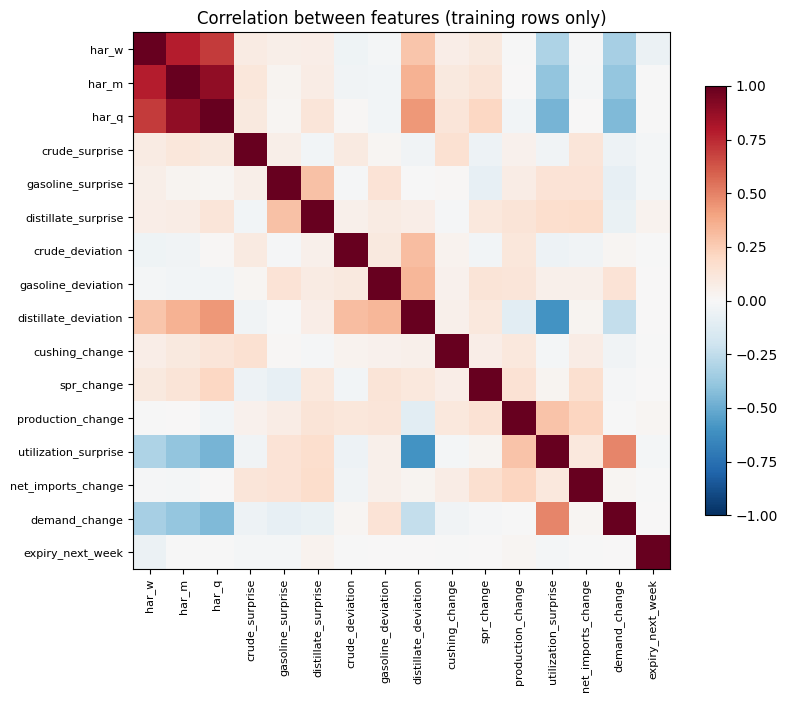

In [30]:
fig, ax = plt.subplots(figsize=(8.5, 7))
matrix = features.loc[train_mask, feature_columns].corr()
labels = [c.removesuffix("_z") for c in matrix.columns]
image = ax.imshow(matrix.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.set_title("Correlation between features (training rows only)")
fig.colorbar(image, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

### 9.5 Histograms, train against test

If a feature's test distribution sits well away from its training one, the model will be
extrapolating there — the same thing the drift table counts, seen directly.

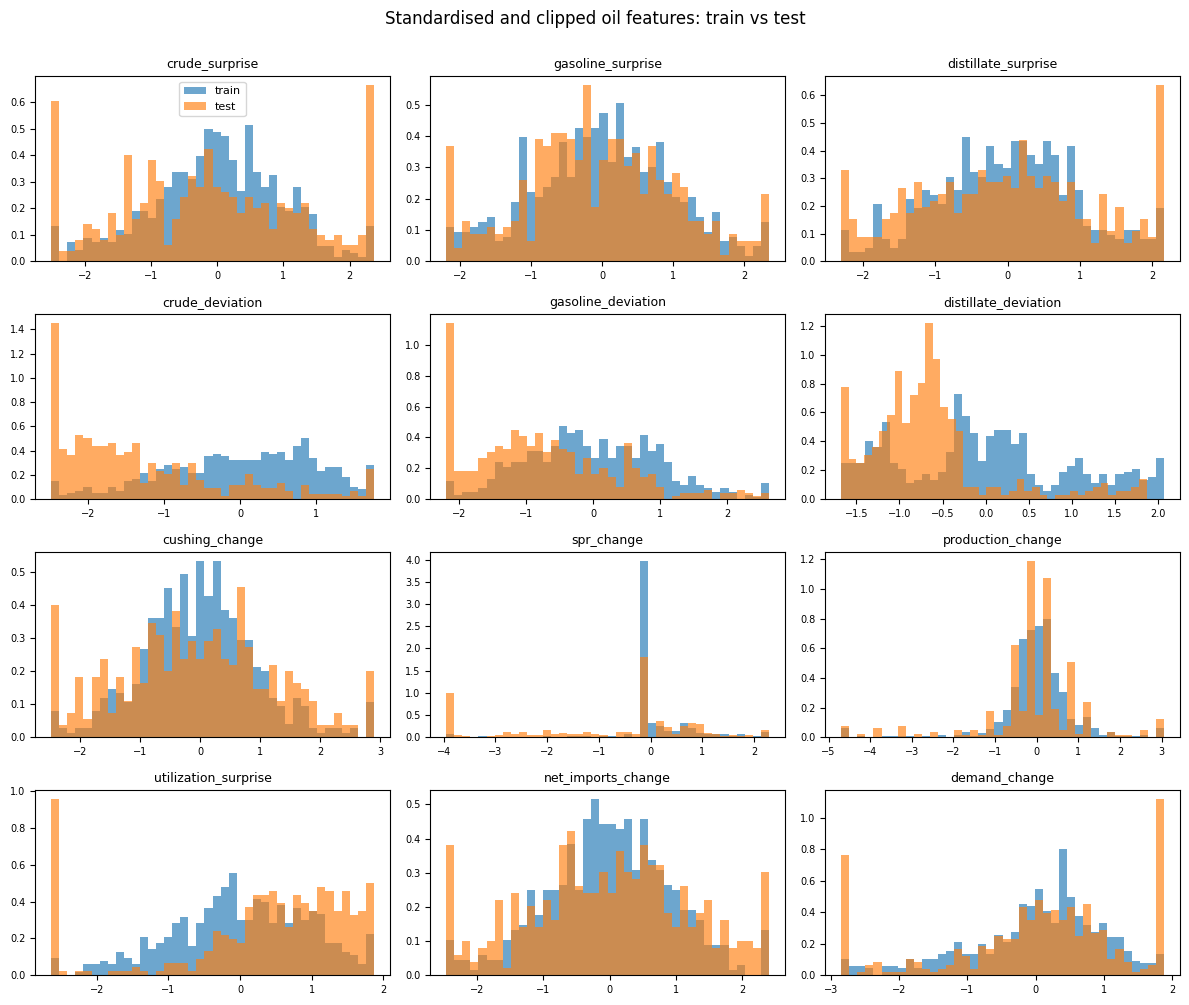

In [31]:
columns = [f"{name}_z" for name in OIL_FEATURES]
fig, axes = plt.subplots(4, 3, figsize=(12, 10))
for ax, column in zip(axes.ravel(), columns):
    ax.hist(features.loc[train_mask, column], bins=40, alpha=0.65,
            label="train", density=True)
    ax.hist(features.loc[splits == "test", column], bins=40, alpha=0.65,
            label="test", density=True)
    ax.set_title(column.removesuffix("_z"), fontsize=9)
    ax.tick_params(labelsize=7)
axes.ravel()[0].legend(fontsize=8)
fig.suptitle("Standardised and clipped oil features: train vs test", y=1.0)
fig.tight_layout()
plt.show()

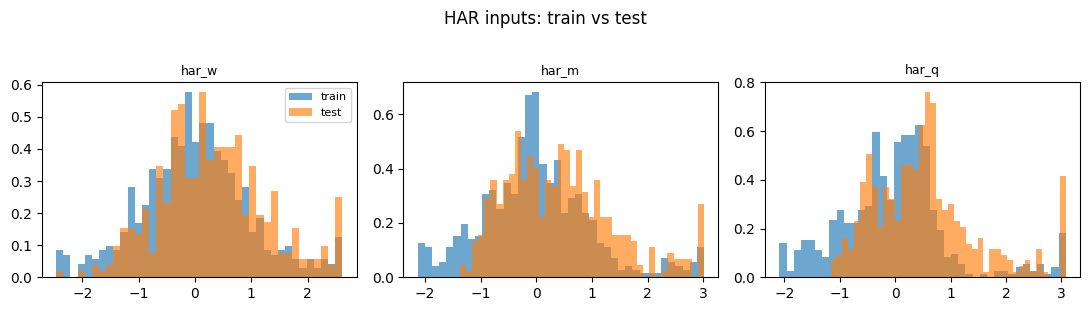

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, column in zip(axes, ["har_w_z", "har_m_z", "har_q_z"]):
    ax.hist(features.loc[train_mask, column], bins=40, alpha=0.65, label="train", density=True)
    ax.hist(features.loc[splits == "test", column], bins=40, alpha=0.65, label="test", density=True)
    ax.set_title(column.removesuffix("_z"), fontsize=9)
axes[0].legend(fontsize=8)
fig.suptitle("HAR inputs: train vs test", y=1.02)
fig.tight_layout()
plt.show()

### 9.6 The PCA scree plot

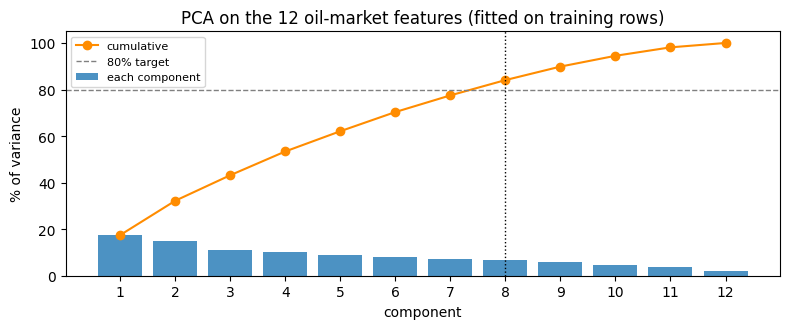

In [33]:
variance = built["pca_variance"]
fig, ax = plt.subplots(figsize=(8, 3.4))
positions = range(1, len(variance) + 1)
ax.bar(positions, variance["explained_variance_pct"], alpha=0.8,
       label="each component")
ax.plot(positions, variance["cumulative_pct"], marker="o", color="darkorange",
        label="cumulative")
ax.axhline(100 * PCA_VARIANCE_TARGET, linestyle="--", linewidth=1, color="grey",
           label=f"{100 * PCA_VARIANCE_TARGET:.0f}% target")
ax.axvline(built["n_components"], linestyle=":", linewidth=1, color="black")
ax.set_xlabel("component")
ax.set_ylabel("% of variance")
ax.set_title(f"PCA on the {len(OIL_FEATURES)} oil-market features "
             "(fitted on training rows)")
ax.set_xticks(list(positions))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 9.7 Past volatility coloured by regime

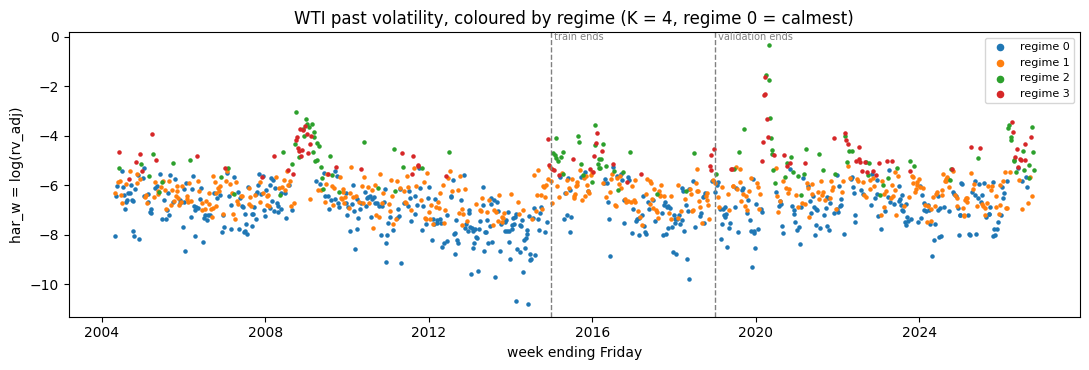

In [34]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for regime in sorted(features["regime"].unique()):
    mask = features["regime"] == regime
    ax.scatter(features.index[mask], features.loc[mask, "har_w"], s=5,
               label=f"regime {regime}")
for boundary, name in ((TRAIN_END, "train ends"), (VALID_END, "validation ends")):
    ax.axvline(pd.Timestamp(boundary), color="grey", linestyle="--", linewidth=1)
    ax.text(pd.Timestamp(boundary), ax.get_ylim()[1], f" {name}", fontsize=7,
            va="top", color="grey")
ax.set_ylabel("har_w = log(rv_adj)")
ax.set_xlabel("week ending Friday")
ax.set_title(f"WTI past volatility, coloured by regime (K = {built['n_regimes']}, "
             "regime 0 = calmest)")
ax.legend(fontsize=8, markerscale=2)
fig.tight_layout()
plt.show()

## 10. Save the features

`data/processed/features.csv` is **git-ignored**: it is derived from the third-party daily
prices, like the stage 2 files, and is regenerated by running the notebooks.

In [35]:
FEATURES_PATH.parent.mkdir(parents=True, exist_ok=True)
features.to_csv(FEATURES_PATH, date_format="%Y-%m-%d")
print(f"{FEATURES_PATH.relative_to(ROOT)}: "
      f"{FEATURES_PATH.stat().st_size / 1024:,.0f} KB, "
      f"{features.shape[0]} rows x {features.shape[1]} columns")

reread = pd.read_csv(FEATURES_PATH, parse_dates=["date", "eia_week"], index_col="date")
assert reread.shape == features.shape
assert reread.index.equals(features.index)
print("read back: identical shape and index")

print("\nthe frozen feature sets:")
for name, columns in feature_sets(built["n_components"]).items():
    print(f"  {name:9s} {len(columns):2d} columns: {columns}")

data/processed/features.csv: 1,112 KB, 1175 rows x 56 columns
read back: identical shape and index

the frozen feature sets:
  base       4 columns: ['har_w_z', 'har_m_z', 'har_q_z', 'expiry_next_week']
  full      16 columns: ['har_w_z', 'har_m_z', 'har_q_z', 'expiry_next_week', 'crude_surprise_z', 'gasoline_surprise_z', 'distillate_surprise_z', 'crude_deviation_z', 'gasoline_deviation_z', 'distillate_deviation_z', 'cushing_change_z', 'spr_change_z', 'production_change_z', 'utilization_surprise_z', 'net_imports_change_z', 'demand_change_z']
  full_pca  12 columns: ['har_w_z', 'har_m_z', 'har_q_z', 'expiry_next_week', 'pc1', 'pc2', 'pc3', 'pc4', 'pc5', 'pc6', 'pc7', 'pc8']


## Decisions to describe in the paper

1. **The sample starts on 2004-04-23, and why.** Every other series reaches back to the
   1980s or early 1990s, but EIA only publishes **Cushing** stocks from 2004-04-09; with
   the one-week release lag and one more week needed to form a change, the first usable
   week is late April 2004. Cushing is kept rather than dropped because it is WTI's
   physical delivery point, and the clearest episode in the sample — WTI settling below
   zero in April 2020 — happened precisely because storage there was filling up. The cost
   is about four years of history.

2. **The target and its timing.** `y` is `log_rv` of week **t+1**. For panel week t, only
   prices up to Friday t and EIA data published by Friday t (the week ending t-7) are
   used; the EIA report released *during* the target week is never used. All rows carry
   exactly a 7-day EIA lag, and the notebook asserts it.

3. **Each feature.** Three HAR inputs (Corsi, 2009): `har_w`, `har_m`, `har_q`, the logs of
   average `rv_adj` over 1, 4 and 12 weeks ending at t. Twelve oil-market features: three
   stock **surprises** (change minus the usual change for the week of the year), three
   **deviations** (level over the usual level, minus 1), and `cushing_change`,
   `spr_change`, `production_change` (a 4-week difference, since weekly production is a
   rounded estimate), `utilization_surprise`, `net_imports_change` (4-week average of
   imports minus exports, against its value 4 weeks earlier) and `demand_change` (4-week
   average of product supplied against the same average a year earlier). Plus
   `expiry_next_week`.

4. **Why changes, surprises and deviations instead of levels.** US crude production more
   than doubled over the sample; crude exports went from nothing to millions of barrels a
   day after the 1975 export ban was lifted in December 2015; the SPR was drawn down
   heavily in 2022. On levels, a model would mostly learn those trends and would not
   transfer from the training years to the test years. Differences and seasonal
   comparisons are on the same footing throughout.

5. **The scarcity hypothesis.** The theory of storage says inventories are a buffer: when
   they are low relative to normal there is little cushion for a shock, so prices should
   move more (Pindyck, 2001; Geman & Ohana, 2009 find low crude inventories go with higher
   volatility). That is what the three `*_deviation` features test, with the expected sign
   being negative — plentiful stocks, calmer prices.

6. **The surprises are measured against the seasonal norm, not against analysts'
   forecasts.** Survey expectations for the EIA report are not freely available. So the
   question this project answers is the narrower one: do *known fundamental conditions*
   predict next week's volatility? It is not a test of whether the market was surprised in
   the sense a trader would mean, and the paper should say so plainly.

7. **The expiry flag.** A WTI contract stops trading 3 business days before the 25th of the
   month before delivery, or 4 if the 25th is not a business day. The calendar is published
   years ahead, so using next week's expiry at Friday t is not look-ahead. The flag is in
   every feature set, so `full` against `base` isolates the EIA data.

8. **Scaling, clipping and drift.** Standardised on training rows only, then clipped to the
   training 1st-99th percentile range so that a linear model cannot extrapolate to absurd
   values. The drift table shows six of the fifteen continuous features more than 10%
   outside the training range in validation or test. The extreme case is
   `crude_deviation`, outside the range in **69%** of validation weeks: in 2015-2017 US
   crude stocks ran so far above their five-year norm, during the shale glut, that the
   feature is effectively saturated through the tuning period. `demand_change` (COVID) and
   `spr_change` (the 2022 drawdown) drift most in the test years. These are real structural
   breaks, not coding errors, and they are a limitation of the design rather than something
   to fix by peeking at later data.

9. **PCA.** Fitted on the training rows of the twelve standardised, clipped oil features.
   Eight components are needed for 80% of the variance and ten for 90%, and the first
   explains only about 17%. The mean absolute correlation between the features is about
   0.1, so there is little to compress: the twelve features carry largely separate
   information rather than three or four underlying factors. `full_pca` is therefore a weak
   dimension reduction, and `full` against `base` is the comparison that matters.

10. **Regimes.** A Gaussian mixture on `har_w` and `wti_ret_w` at week t, fitted on
    training rows, renumbered so regime 0 is calmest. The BIC rule — the smallest K within
    10 points of the best BIC — selects **K = 4**, because BIC keeps falling as regimes are
    added. But the stability check contradicts it: at K = 4 only **39%** of training weeks
    keep the same label across five random seeds (ARI 0.50), while K = 2 is perfectly
    stable and K = 3 is stable at 98% (ARI 0.98). A solution whose labels move with the
    seed cannot support a regime-by-regime evaluation, so the paper should report both
    criteria and justify the K it uses. `build_features(n_regimes=3)` switches the choice.

11. **Missing values.** Inside an EIA series, a single missing week is carried forward from
    the week before (past values only) and longer gaps are left missing. Stage 2 showed the
    only gaps are six weeks in 1982-83 and one in 1991, all long before this sample starts,
    so **no row is dropped** for missing values. The modelling sample is defined by WTI, the
    main series: Brent's one unusable week (2018-12-28, too few trading days) would
    otherwise blank `brent_har_q` for twelve weeks and delete the start of the WTI test
    period with it, so Brent columns keep NaN there and the Brent robustness run drops its
    own rows.

12. **The feature list is frozen.** It lives in `src/config.py` as `BASE_FEATURES` and
    `OIL_FEATURES`. Nothing is added in stage 4; the comparison is `full` against `base`
    and `full_pca` against `base`.

**Next:** `04_models.ipynb` fits HAR, GARCH, Lasso, random forest and LSTM on `log_rv`, and
scores them on the variance scale with QLIKE, MSE and Mincer-Zarnowitz, as set up in
`src/evaluation.py`.